# Hypothesis (H2-A): 

#### Small objects suffer from low confidence and missed detections because their spatial features weaken in deeper layers, making the detection head overly dependent on background context instead of intrinsic object cues.

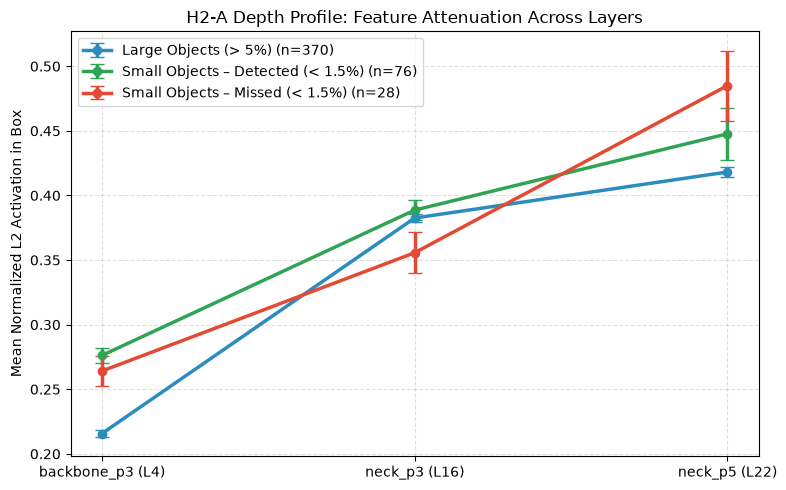

In [1]:
from pathlib import Path
import xml.etree.ElementTree as ET
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.5

# Load paths & model
base_dir = Path("/home/mader/Documents/AI/3. Semester/AI_visualization/AI_visualization/AI-Aided Pair/Phase 2")
voc_dir = Path("/home/mader/Documents/AI/3. Semester/AI_visualization/AI_visualization/Trash/Andres-Simon/phase1/Simon/archive/VOC_dataset/VOCdevkit/VOC2007")
model = YOLO(base_dir / "yolo26n.pt")

VOC_TO_COCO_ID = {
    "aeroplane": 4,
    "bicycle": 1,
    "bird": 14,
    "boat": 8,
    "bottle": 39,
    "bus": 5,
    "car": 2,
    "cat": 15,
    "chair": 56,
    "cow": 19,
    "diningtable": 60,
    "dog": 16,
    "horse": 17,
    "motorbike": 3,    
    "person": 0,
    "pottedplant": 58, 
    "sheep": 18,
    "sofa": 57,        
    "train": 6,
    "tvmonitor": 62,
}

def get_gt_objects(xml_path):
    root = ET.parse(xml_path).getroot()
    objs = []
    for obj in root.findall("object"):
        if int(obj.find("difficult").text) == 1:    # discard impossible images
            continue
        name = obj.find("name").text
        b = obj.find("bndbox")
        box = [
            float(b.find("xmin").text),
            float(b.find("ymin").text),
            float(b.find("xmax").text),
            float(b.find("ymax").text),
        ]
        objs.append((name, box))
    return objs

def calc_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_of_box_1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area_of_box_2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    return inter / (area_of_box_1 + area_of_box_2 - inter + 1e-8) # normalized on sum of area of both boxes

def get_box_mean(heatmap, box, img_w, img_h):
    h, w = heatmap.shape
    x1 = max(0, int(box[0] * w / img_w))  # w / img_w to downscale from large image to smaller heatmap
    y1 = max(0, int(box[1] * h / img_h))
    x2 = min(w, int(np.ceil(box[2] * w / img_w)))
    y2 = min(h, int(np.ceil(box[3] * h / img_h)))

    return float(heatmap[y1:y2, x1:x2].mean())  # mean over all pixelvalues in the BB (is the activation)

# Register hooks for the 3 layers
layers = {"backbone_p3 (L4)": 4, "neck_p3 (L16)": 16, "neck_p5 (L22)": 22}
acts = {}
hooks = []

for name, idx in layers.items():
    h = model.model.model[idx].register_forward_hook(
        lambda m, i, o, layer_name=name: acts.update({layer_name: o.detach().cpu()}))
    hooks.append(h)

large_objs = {"backbone_p3 (L4)": [], "neck_p3 (L16)": [], "neck_p5 (L22)": []}
small_detected = {"backbone_p3 (L4)": [], "neck_p3 (L16)": [], "neck_p5 (L22)": []}
small_missed = {"backbone_p3 (L4)": [], "neck_p3 (L16)": [], "neck_p5 (L22)": []}

# saves directory of first 250 pictures
img_files = sorted((voc_dir / "JPEGImages").glob("*.jpg"))[:250]

for img_path in img_files:
    # get ground truth
    xml_path = voc_dir / "Annotations" / f"{img_path.stem}.xml"
    gt_objs = get_gt_objects(xml_path)
    if not gt_objs:
        continue

    img_w, img_h = Image.open(img_path).size
    img_area = img_w * img_h

    # do prediction
    res = model.predict(img_path, conf=CONF_THRESHOLD, verbose=False)[0]
    pred_boxes = res.boxes.xyxy.cpu().numpy()
    pred_classes = res.boxes.cls.cpu().numpy().astype(int)

    # Compute heatmaps per layer
    heatmaps = {}
    for name in layers:
        hm = torch.norm(acts[name].squeeze(0), p=2, dim=0).numpy()  # L2-Norm over all channels for each pixel (C,H,W)->(H,W)
        heatmaps[name] = (hm - hm.min()) / (hm.max() - hm.min() + 1e-8)

    for cls_name, gt_box in gt_objs:
        cls_id = VOC_TO_COCO_ID[cls_name]
        rel_area = ((gt_box[2] - gt_box[0]) * (gt_box[3] - gt_box[1])) / img_area

        # Check if object was detected
        is_detected = False
        for p_box, p_cls in zip(pred_boxes, pred_classes):
            if p_cls == cls_id and calc_iou(gt_box, p_box) >= IOU_THRESHOLD:
                is_detected = True
                break

        # Select the appropriate list
        if rel_area > 0.05:
            target_dict = large_objs
        elif rel_area < 0.015:
            target_dict = small_detected if is_detected else small_missed
        else:
            continue    # discard medium sized objects

        for name in layers:
            val = get_box_mean(heatmaps[name], gt_box, img_w, img_h)
            target_dict[name].append(val)

for h in hooks:
    h.remove()

# Plotting
layer_names = list(layers.keys())
x = np.arange(len(layer_names))

plot_groups = [
    ("Large Objects (> 5%)", large_objs, "#2b8cbe"),
    ("Small Objects – Detected (< 1.5%)", small_detected, "#31a354"),
    ("Small Objects – Missed (< 1.5%)", small_missed, "#e34a33"),
]

plt.figure(figsize=(8, 5))
for label, data, color in plot_groups:
    means = [np.mean(data[l]) for l in layer_names]  # mean over all activation means in the picture
    sems = [np.std(data[l]) / np.sqrt(len(data[l])) for l in layer_names]
    n = len(data[layer_names[0]])
    plt.errorbar(x, means, yerr=sems, marker="o", linewidth=2.5, capsize=5, color=color, label=f"{label} (n={n})")

plt.xticks(x, layer_names)
plt.ylabel("Mean Normalized L2 Activation in Box")
plt.title("H2-A Depth Profile: Feature Attenuation Across Layers")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

Mean Context Gain (Small Objects): +22.6% (Median: +9.1%)
Mean Context Gain (Large Objects): -2.6% (Median: -1.6%)


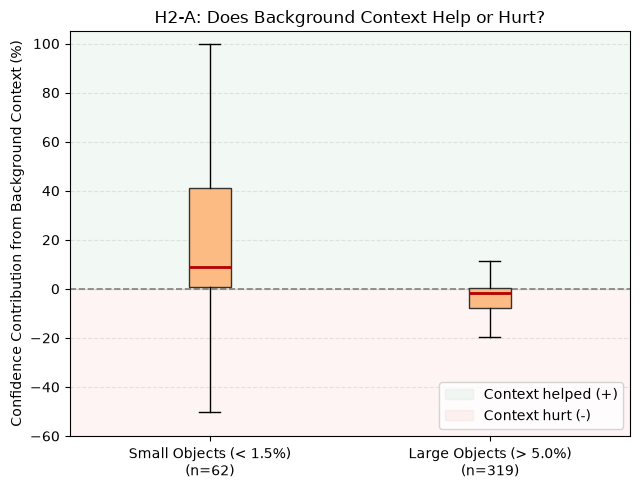

In [2]:
# Make background outside the BB gray (by placing BB in gray image)
def mask_background(pil_img, box, pad=4):
    arr = np.array(pil_img)
    bg_masked = np.full_like(arr, 114)  # 114 = gray
    h, w = arr.shape[:2]

    x1 = max(0, int(np.floor(box[0])) - pad)
    y1 = max(0, int(np.floor(box[1])) - pad)
    x2 = min(w, int(np.ceil(box[2])) + pad)
    y2 = min(h, int(np.ceil(box[3])) + pad)

    bg_masked[y1:y2, x1:x2] = arr[y1:y2, x1:x2]
    return Image.fromarray(bg_masked)

def get_best_conf(pred_res, gt_box, cls_id):

    boxes = pred_res.boxes.xyxy.cpu().numpy()
    clss = pred_res.boxes.cls.cpu().numpy().astype(int)
    confs = pred_res.boxes.conf.cpu().numpy()

    # for each object we look for the BB with the highest conf that predicts the correct class and has large enough IoU
    # since there can exist multiple BBs per object
    best_c = 0.0
    for b, cl, c in zip(boxes, clss, confs):    
        if cl == cls_id and calc_iou(gt_box, b) >= IOU_THRESHOLD:
            if c > best_c:
                best_c = float(c)
    return best_c

# Context gain for small vs. large objects
small_context_gain, large_context_gain = [], []

for img_path in img_files:

    gt_objs = get_gt_objects(voc_dir / "Annotations" / f"{img_path.stem}.xml")

    orig_img = Image.open(img_path).convert("RGB")
    img_w, img_h = orig_img.size
    img_area = img_w * img_h

    res_orig = model.predict(orig_img, conf=CONF_THRESHOLD, verbose=False)[0]

    for cls_name, gt_box in gt_objs:
        cls_id = VOC_TO_COCO_ID[cls_name]
        rel_area = ((gt_box[2] - gt_box[0]) * (gt_box[3] - gt_box[1])) / img_area

        conf_with_ctx = get_best_conf(res_orig, gt_box, cls_id)
        if conf_with_ctx < 0.40:  # Only evaluate objects confidently detected in the original image
            continue

        is_small = rel_area < 0.015 
        is_large = rel_area > 0.05 
        if not (is_small or is_large):  # discard medium sized objects
            continue

        # Remove background context and re-run inference
        masked_img = mask_background(orig_img, gt_box)
        res_masked = model.predict(masked_img, conf=0.01, verbose=False)[0]
        conf_no_ctx = get_best_conf(res_masked, gt_box, cls_id)

        # Positive = context helped boost confidence; Negative = context hurt confidence
        ctx_gain = ((conf_with_ctx - conf_no_ctx) / conf_with_ctx) * 100.0

        if is_small:
            small_context_gain.append(ctx_gain)
        else:
            large_context_gain.append(ctx_gain)

print(f"Mean Context Gain (Small Objects): {np.mean(small_context_gain):+.1f}% (Median: {np.median(small_context_gain):+.1f}%)")
print(f"Mean Context Gain (Large Objects): {np.mean(large_context_gain):+.1f}% (Median: {np.median(large_context_gain):+.1f}%)")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.axhspan(0, 110, color="#31a354", alpha=0.06, label="Context helped (+)")
ax.axhspan(-110, 0, color="#e34a33", alpha=0.06, label="Context hurt (-)")
ax.axhline(0, color="gray", linestyle="--", linewidth=1.2)

ax.boxplot(
    [small_context_gain, large_context_gain],
    tick_labels=[
        f"Small Objects (< 1.5%)\n(n={len(small_context_gain)})",
        f"Large Objects (> 5.0%)\n(n={len(large_context_gain)})",
    ],
    patch_artist=True,
    showfliers=False,  # Hide outlier circles
    boxprops=dict(facecolor="#fdbb84", edgecolor="#333333"),
    medianprops=dict(color="#b30000", linewidth=2),
)

ax.set_ylim(-60, 105)
ax.set_ylabel("Confidence Contribution from Background Context (%)")
ax.set_title("H2-A: Does Background Context Help or Hurt?")
ax.legend(loc="lower right", frameon=True)
ax.grid(True, axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusion
Our results only partially support Hypothesis H2-A. First, looking at the activation across layers, small objects do not suffer from a strong drop in feature activation. However, the context ablation test confirms that small objects depend heavily on their surrounding background: removing the context causes a clear confidence drop for small objects (median around +9%, and up to +100% for many cases), whereas large objects are almost unaffected (median around −2%). In short, small objects are missed not because their features fade out across layers, but because they lack strong initial features and rely heavily on background context to be detected.

# Hypothesis (H2-B): 
#### Hypothesis (H2-B): In crowded or occluded scenes, feature representations of overlapping objects blend together in the neck's spatial feature maps, causing the model's spatial attention to focus primarily on the unoccluded foreground object while suppressing or shifting the activation peak of the occluded object.

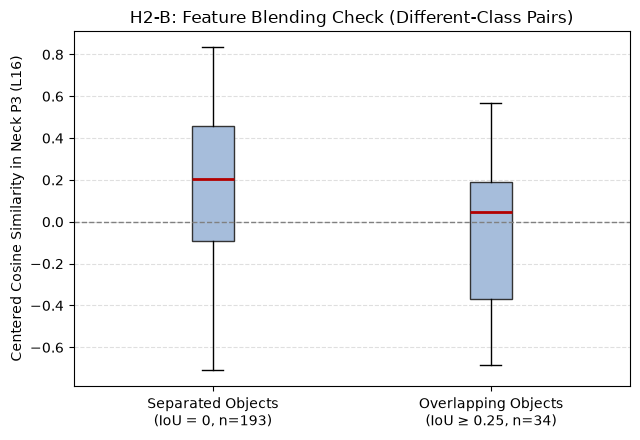

In [30]:
# In neck_p3 (L16), we represent each object by its mean channel vector (after centering the feature map).
# We compute the cosine similarity between different-class object pairs—comparing separated pairs (IoU = 0)
# against overlapping pairs (IoU >= 0.25, using only their non-overlapping visible parts).
# Regardless of the specific object classes, if overlapping pairs have a higher average similarity than
# separated ones, spatial overlap blends their feature representations together.

model = YOLO(base_dir / "yolo26n.pt")

acts_h2b = {}
hook_h2b = model.model.model[16].register_forward_hook(
    lambda m, i, o: acts_h2b.update({"neck_p3": o.detach().cpu()})
)

def box_mask(box, w, h, img_w, img_h):
    m = np.zeros((h, w), dtype=bool)
    x1 = int(box[0] * w / img_w)
    y1 = int(box[1] * h / img_h)
    x2 = max(x1 + 1, int(box[2] * w / img_w))   # ensure that cell has at least size 1
    y2 = max(y1 + 1, int(box[3] * h / img_h))
    m[y1:y2, x1:x2] = True
    return m

def cos_sim(v1, v2):
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-8)

separated_sims, overlap_sims = [], []

for img_path in img_files:
    gt_objs = get_gt_objects(voc_dir / "Annotations" / f"{img_path.stem}.xml")

    orig_img = Image.open(img_path).convert("RGB")
    img_w, img_h = orig_img.size
    model.predict(orig_img, conf=0.25, verbose=False)

    feat_map = acts_h2b["neck_p3"].squeeze(0).numpy()
    feat_map = feat_map - feat_map.mean(axis=(1, 2), keepdims=True)
    _, h, w = feat_map.shape

    # calc cosine similarity of all pairs of objects depending on their IoU
    for i in range(len(gt_objs)):
        for j in range(i + 1, len(gt_objs)):
            cls1, box1 = gt_objs[i]
            cls2, box2 = gt_objs[j]
            if cls1 == cls2:    # we are not interested in objects of same class since the have anyway similar feature vectors
                continue

            iou = calc_iou(box1, box2)
            if iou == 0.0:
                m1 = box_mask(box1, w, h, img_w, img_h)     # all cells within the BB are labeled as True
                m2 = box_mask(box2, w, h, img_w, img_h)
                # feat_map.shape = (C, h, w), feat_map[:, m1].shape = (C, N) where all N vectors of dim C are labelled as True
                separated_sims.append(cos_sim(feat_map[:, m1].mean(axis=1), feat_map[:, m2].mean(axis=1))) # mean over Channels

            elif iou >= 0.25:
                m1 = box_mask(box1, w, h, img_w, img_h)
                m2 = box_mask(box2, w, h, img_w, img_h)
                m1_clean = m1 & ~m2     # all cells that belong to m1 but not to m2
                m2_clean = m2 & ~m1
                if np.any(m1_clean) and np.any(m2_clean):  # make sure that only masks with at least 1 True value are considered
                    overlap_sims.append(cos_sim(feat_map[:, m1_clean].mean(axis=1), feat_map[:, m2_clean].mean(axis=1)))

hook_h2b.remove()

plt.figure(figsize=(6.5, 4.5))
plt.boxplot(
    [separated_sims, overlap_sims],
    tick_labels=[
        f"Separated Objects\n(IoU = 0, n={len(separated_sims)})",
        f"Overlapping Objects\n(IoU ≥ 0.25, n={len(overlap_sims)})",
    ],
    patch_artist=True,
    showfliers=False,
    boxprops=dict(facecolor="#a6bddb", edgecolor="#333333"),
    medianprops=dict(color="#b30000", linewidth=2),
)
plt.axhline(0.0, color="gray", linestyle="--", linewidth=1)
plt.ylabel("Centered Cosine Similarity in Neck P3 (L16)")
plt.title("H2-B: Feature Blending Check (Different-Class Pairs)")
plt.grid(True, axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Hypothesis H2-B is not supported by our internal feature analysis. Comparing centered channel vectors in neck_p3 (L16) between different-class object pairs shows no increase in feature similarity when objects overlap ($\text{IoU} \ge 0.25$, median $\approx -0.02$, $n=34$) compared to separated objects ($\text{IoU} = 0$, median $\approx +0.15$, $n=193$). Thus, the confidence drop in crowded scenes is not caused by spatial feature blending or suppression in the neck, but rather by the loss of visible object area and context needed by the detection head to confidently reconstruct the full object.